# Peptide COA coverage: what is missing?

**A missing measurement is not a failed test.** This notebook measures availability in TitrateLab's **2026-10-12** aggregate release and checks every derived missing count against its manifest. It describes **96,805 included published report entries across 68 compounds and blends**, not a random market sample or a count of unique certificates.

The main question is: *Which measurements can this release support, and which report entries lack the fields needed for an analysis?* A blank field can reflect selective testing, publication, collection or extraction. The aggregates do not identify the cause.

Source: [TitrateLab data catalog](https://titratelab.com/data), [collection and interpretation methodology](https://titratelab.com/methodology), and [archived dataset DOI](https://doi.org/10.5281/zenodo.23551719). This analysis preserves the dataset files unchanged.


This notebook defaults to the repository's fixed `data/releases/2026-10-12/` snapshot when run from the repository root or the `notebooks/` directory. It never substitutes `data/latest/`.

Install dependencies from the repository root with `python -m pip install -r requirements.txt pandas jupyterlab`, then open this notebook and **Run All**. No internet connection, GPU or private data is required after dependencies and the repository are downloaded.

For an extracted archive elsewhere, set `TITRATELAB_DATA_DIR` to the directory containing `manifest.json` and `compounds.csv`. On Kaggle, attach **TitrateLab Peptide COA Aggregates — 2026-10-12**. The manifest supplies the expected CSV checksum and row count; mismatches stop execution.


In [1]:
from pathlib import Path
import os, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

configured_dir = os.environ.get("TITRATELAB_DATA_DIR")
if configured_dir:
    root = Path(configured_dir).expanduser()
else:
    local_release_dirs = [
        Path("data/releases/2026-10-12"),
        Path("../data/releases/2026-10-12"),
    ]
    root = next((p for p in local_release_dirs if (p / "manifest.json").is_file()),
                Path("/kaggle/input"))
assert root.is_dir(), "Run from the repository root/notebooks directory, or set TITRATELAB_DATA_DIR."
matching = []
for path in root.rglob("manifest.json"):
    candidate = json.loads(path.read_text())
    if candidate.get("version") == "2026-10-12" and candidate.get("projection", {}).get("snapshot_id") == "20261012T021040Z":
        matching.append((path, candidate))
assert len(matching) == 1, "Attach exactly one copy of the October 12 TitrateLab release."
manifest_path, manifest = matching[0]
csv_path = manifest_path.parent / "compounds.csv"
actual_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
assert actual_sha256 == manifest["files"]["compounds.csv"]["sha256"], "Source CSV checksum mismatch."
compounds = pd.read_csv(csv_path)
assert len(compounds) == manifest["files"]["compounds.csv"]["rows"] == 68
assert compounds["compound"].is_unique
print("Release:", manifest["version"])
print("Observed through:", manifest["observed_through"])
print("Verified compounds.csv SHA-256:", actual_sha256)
print("Compound/blend rows:", len(compounds))


Release: 2026-10-12
Observed through: 2026-10-12T00:23:06Z
Verified compounds.csv SHA-256: 939a8ea980a6e50d36e7fe6e699f39438c114e51105bccd8878a446c8bc0f048
Compound/blend rows: 68


## Establish the denominator before counting measurements

`test_records` counts entries included in each compound aggregate. The release excludes cells with fewer than 10 entries. Its 96,805 included entries are the denominator for this notebook's overall coverage percentages; the larger published corpus and other aggregate tables have different eligibility rules.

`purity_results` counts **strictly positive** reported values. Zero-purity or unidentified-target entries have their own field, `zero_identity_results`. Omitting that second field would incorrectly inflate missingness.

**Broader reconciliation limit.** The manifest reports 116,363 published entries, which is 19,558 more than the 96,805 included entries. Its noncanonical/invalid and small-cell exclusion counters sum to 17,898, leaving 1,660 entries unexplained by those two counters. We do not assign them an inferred category. The eligible-named-to-included bridge does reconcile, and the coverage calculations below use the 96,805 included entries.


In [2]:
count_fields = ["test_records", "purity_results", "zero_identity_results", "quantity_results", "endotoxin_results", "verifiable_records"]
for field in count_fields:
    assert compounds[field].notna().all(), f"Unexpected missing aggregate count: {field}"
    assert (compounds[field] >= 0).all() and (compounds[field] % 1 == 0).all()
    assert (compounds[field] <= compounds["test_records"]).all()
assert (compounds["test_records"] >= manifest["minimum_cell_size"]).all()
assert (compounds["purity_results"] + compounds["zero_identity_results"] <= compounds["test_records"]).all()
totals = compounds[count_fields].sum().astype(int)
N = int(totals["test_records"])
assert N == manifest["coverage"]["included_records"] == 96805
assert len(compounds) == manifest["coverage"]["included_compounds"]
assert N + manifest["coverage"]["excluded_small_cell_records"] == manifest["coverage"]["eligible_named_records"]
display(totals.rename("included_entry_count").to_frame())


,included_entry_count
test_records,96805
purity_results,86594
zero_identity_results,671
quantity_results,68267
endotoxin_results,12516
verifiable_records,95221


## Reconcile availability and missingness

The first category includes positive-purity **plus** zero-purity/unidentified-target entries. Quantity means a tested quantity expressed as deviation from the **printed label**. An endotoxin result includes below-detection outcomes. A verification URL is provenance availability, not a measurement or certification by TitrateLab.

Each percentage below uses all included report entries as its denominator. **Do not add missing counts across categories:** one report entry may lack several fields. These aggregate files cannot tell us how many entries lack every measurement or which fields are jointly missing.


In [3]:
definitions = [
    ("Purity / target status", int(totals["purity_results"] + totals["zero_identity_results"]), "included_records_without_measured_purity"),
    ("Quantity vs printed label", int(totals["quantity_results"]), "included_records_without_label_quantity_deviation"),
    ("Endotoxin result", int(totals["endotoxin_results"]), "included_records_without_endotoxin_result"),
    ("Verification URL", int(totals["verifiable_records"]), "included_records_without_verification_url"),
]
coverage = pd.DataFrame([
    {"field": label, "available_entries": present, "missing_entries": N-present,
     "denominator_entries": N, "available_pct": 100*present/N, "missing_pct": 100*(N-present)/N,
     "manifest_missing_entries": manifest["missing_data"][manifest_key]}
    for label, present, manifest_key in definitions
]).set_index("field")
assert (coverage["missing_entries"] == coverage["manifest_missing_entries"]).all()
assert (coverage["available_entries"] + coverage["missing_entries"] == N).all()
print("All four missing counts reconcile exactly with manifest.json.")
display(coverage.round(2))
print("Separate zero-purity/unidentified-target entries:", int(totals["zero_identity_results"]))


All four missing counts reconcile exactly with manifest.json.


,available_entries,missing_entries,denominator_entries,available_pct,missing_pct,manifest_missing_entries
field,,,,,,
Purity / target status,87265,9540,96805,90.15,9.85,9540
Quantity vs printed label,68267,28538,96805,70.52,29.48,28538
Endotoxin result,12516,84289,96805,12.93,87.07,84289
Verification URL,95221,1584,96805,98.36,1.64,1584


Separate zero-purity/unidentified-target entries: 671


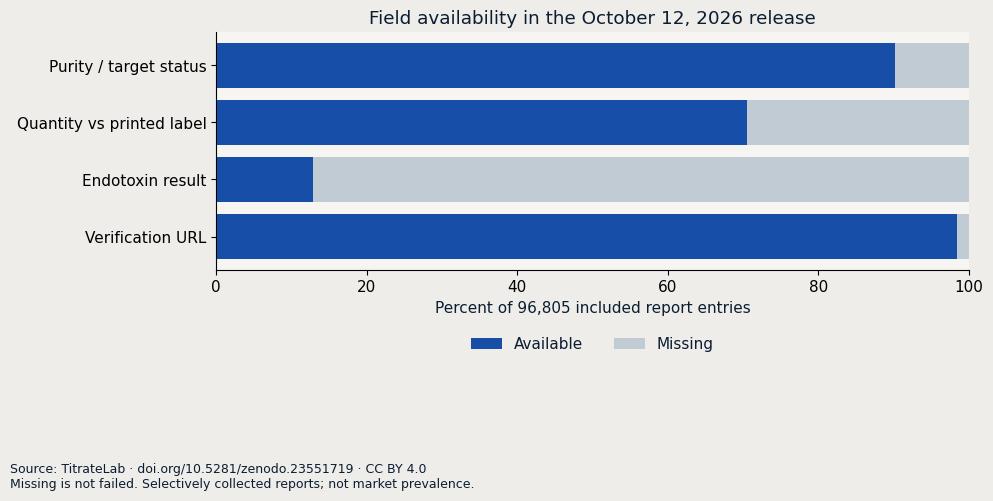

In [4]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.facecolor": "#f6f5f1", "figure.facecolor": "#eeedea",
                     "text.color": "#0b1d30", "axes.labelcolor": "#0b1d30"})
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(coverage.index, coverage["available_pct"], color="#174fa8", label="Available")
ax.barh(coverage.index, coverage["missing_pct"], left=coverage["available_pct"], color="#c1cbd3", label="Missing")
ax.invert_yaxis()
ax.set(xlim=(0,100), xlabel="Percent of 96,805 included report entries",
       title="Field availability in the October 12, 2026 release")
ax.legend(loc="lower center", bbox_to_anchor=(0.5,-0.4), ncols=2, frameon=False)
for side in ("top", "right"): ax.spines[side].set_visible(False)
fig.text(0.01, 0.01, "Source: TitrateLab · doi.org/10.5281/zenodo.23551719 · CC BY 4.0\nMissing is not failed. Selectively collected reports; not market prevalence.", fontsize=9)
fig.tight_layout(rect=(0,0.12,1,1))
fig.savefig("titratelab-field-availability-2026-10-12.png", dpi=160, bbox_inches="tight")
plt.show()
coverage.to_csv("field-availability-2026-10-12.csv")


## Explore a compound with its own denominator

Change `COMPOUND_SEARCH` below. A substring can match a compound and blends containing it; inspect all returned names. Each row uses that compound's `test_records`, **not the whole release**, as its denominator. Percentages describe recorded-field availability, not pass rates. Small counts can produce unstable comparisons; this is not a vendor ranking.


In [5]:
COMPOUND_SEARCH = "semaglutide"
view = compounds.loc[compounds["compound"].str.contains(COMPOUND_SEARCH, case=False, regex=False)].copy()
view["purity_or_target_status_available"] = view["purity_results"] + view["zero_identity_results"]
for field in ["purity_or_target_status_available", "quantity_results", "endotoxin_results", "verifiable_records"]:
    view[field + "_pct"] = 100 * view[field] / view["test_records"]
columns = ["compound", "test_records", "purity_results", "zero_identity_results",
           "purity_or_target_status_available_pct", "quantity_results_pct",
           "endotoxin_results_pct", "verifiable_records_pct"]
if view.empty:
    print("No matching compound rows. No denominator is available for this search.")
else:
    display(view[columns].sort_values("test_records", ascending=False).round(2))


,compound,test_records,purity_results,zero_identity_results,purity_or_target_status_available_pct,quantity_results_pct,endotoxin_results_pct,verifiable_records_pct
56,Semaglutide,2393,2190,9,91.89,75.97,8.07,98.58
20,Cagrilintide + Semaglutide,50,22,0,44.00,2.00,4.00,98.00


## Keep date coverage and analytical denominators separate

The manifest reports entries without a printed test date. That count is distinct from measurement missingness. Monthly aggregate tables can have their own small-cell suppression and eligible populations; summing a different table is not automatically a replacement denominator.

Purity means/medians exclude zero and unidentified-target entries. Quantity-within-10% percentages use **quantity results**, not all reports. This notebook does not average per-compound means into an overall purity figure or reconstruct exact quantity counts from rounded percentages.


In [6]:
dated = manifest["coverage"]["included_records_with_test_month"]
undated = manifest["missing_data"]["included_records_without_test_date"]
assert dated + undated == N
print(f"Included entries with test month: {dated:,} / {N:,} ({100*dated/N:.2f}%)")
print(f"Included entries without test date: {undated:,} / {N:,} ({100*undated/N:.2f}%)")
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == actual_sha256
print("Input CSV unchanged after analysis.")


Included entries with test month: 93,537 / 96,805 (96.62%)
Included entries without test date: 3,268 / 96,805 (3.38%)
Input CSV unchanged after analysis.


## Interpretation and reuse

This notebook answers a coverage question: it shows which fields are present in this collected release and reproduces the manifest's missingness counts. It does **not** estimate failure prevalence, product safety, supplier quality or market share. Missingness causes and joint measurement coverage cannot be recovered from these aggregates.

Testing and publication are selective; extraction can be imperfect. Report entries are not guaranteed to be unique certificates. A test describes a submitted sample on its test date, not all vials, an entire batch or current products. Unresolved names, non-peptide analytical work, unpublished records and small cells are excluded. No vendor, client, batch or certificate identity appears in these tables. This is not medical advice.

For source context, read the [release documentation and schema](https://github.com/TitrateLab/peptide-coa-analysis/releases/tag/v2026-10-12) and [TitrateLab methodology](https://titratelab.com/methodology). Use the [public lab-report catalog](https://titratelab.com/coa) to examine original report evidence; its current count is separate from this fixed snapshot.

**Suggested citation:** TitrateLab. (2026). *TitrateLab peptide COA analysis: vendor-blind aggregates of 96,805 published lab reports (release 2026-10-12)* (Version 2026-10-12) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.23551719. Data licensed CC BY 4.0; this notebook is a derived coverage analysis. Attribute TitrateLab and indicate modifications when reusing outputs.
